# Az ML-ERGM eredményeihez tartozó táblázatok és ábrák összeállítása

In [1]:
import pandas as pd

results = "ml_ergm_nested_model8_results.xlsx"
# results = "C:/ELTE/Szakdoga/data/végső ml ergm/ml_ergm_2015_2024_nested_model8_results.xlsx"

coefficients = pd.read_excel(results, sheet_name="coefficients")

## Ellenőrzések

In [2]:
display(coefficients.head())
print("Oszlopok:", coefficients.columns.tolist())

for col in ["Group", "Label", "Term"]:
    if col in coefficients.columns:
        print(f"\n{col} értékei:")
        print(coefficients[col].dropna().unique())

,Year,Term,Estimate,Std_Error,MCMC_pct,z_value,p_value,Group,Label
0,2015,L(1)~edges,-26.075794,1.864003,0,-13.989137,1.816020e-44,Layer_edges,L(1)~edges
1,2015,L(2)~edges,-26.997586,1.924126,0,-14.031093,1.005897e-44,Layer_edges,L(2)~edges
2,2015,L(3)~edges,-27.066448,1.951521,0,-13.869408,9.707425e-44,Layer_edges,L(3)~edges
3,2015,L(4)~edges,-27.521539,1.997456,0,-13.778298,3.442958e-43,Layer_edges,L(4)~edges
4,2015,L(1)~mutual,0.683492,0.109679,0,6.231743,4.612733e-10,Layer_mutual,L(1)~mutual


Oszlopok: ['Year', 'Term', 'Estimate', 'Std_Error', 'MCMC_pct', 'z_value', 'p_value', 'Group', 'Label']

Group értékei:
<ArrowStringArray>
['Layer_edges', 'Layer_mutual', 'Node_covariate', 'Dyadic_control']
Length: 4, dtype: str

Label értékei:
<ArrowStringArray>
[                 'L(1)~edges',                  'L(2)~edges',
                  'L(3)~edges',                  'L(4)~edges',
                 'L(1)~mutual',                 'L(2)~mutual',
                 'L(3)~mutual',                 'L(4)~mutual',
 'High-tech export (outgoing)', 'High-tech export (incoming)',
   'GDP per capita (outgoing)',   'GDP per capita (incoming)',
      'Labor force (outgoing)',      'Labor force (incoming)',
                'Log distance',             'Common language',
       'Colonial relationship',               'Common border']
Length: 18, dtype: str

Term értékei:
<ArrowStringArray>
[           'L(1)~edges',            'L(2)~edges',            'L(3)~edges',
            'L(4)~edges',           

## Négypaneles ábra a kölcsönösség rétegspecifikus becsléseiről konfidencia-intervallumokkal

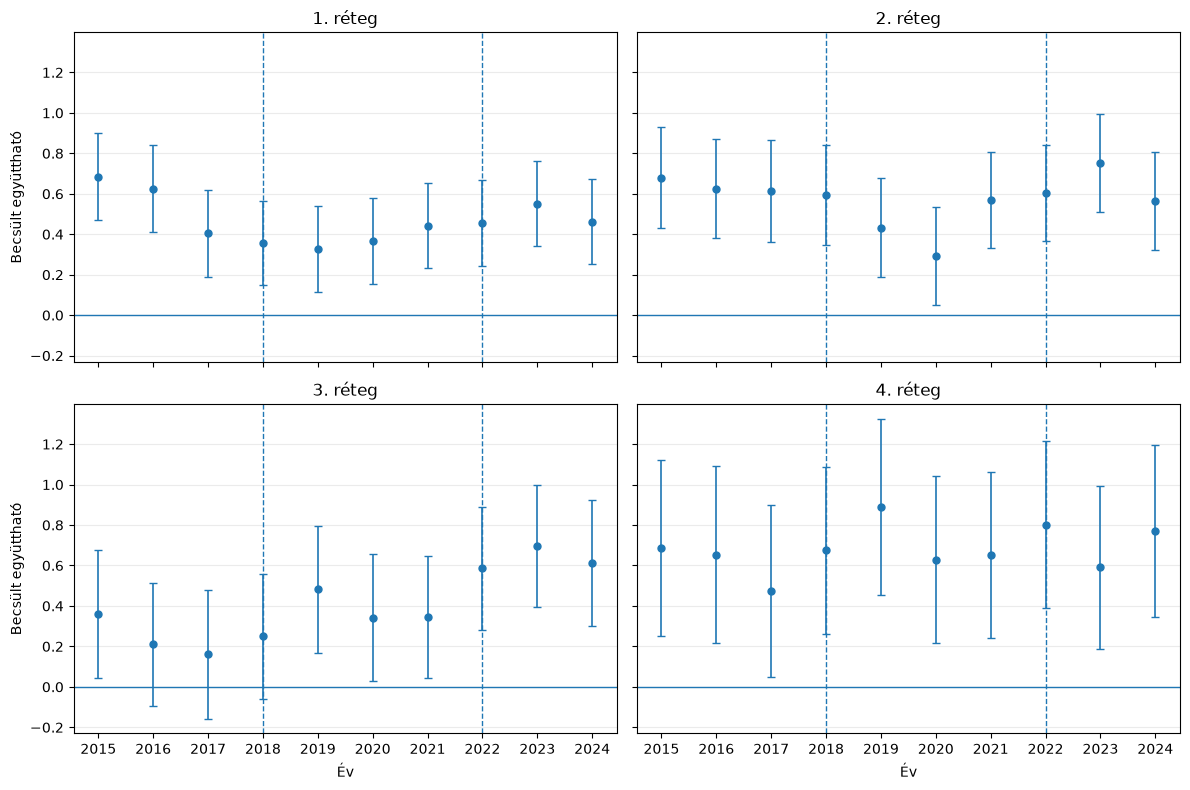

In [3]:
import matplotlib.pyplot as plt

# Mutual változók kiválasztása
mutual_labels = [
    "L(1)~mutual",
    "L(2)~mutual",
    "L(3)~mutual",
    "L(4)~mutual"
]

mutual = coefficients[
    (coefficients["Group"] == "Layer_mutual") &
    (coefficients["Label"].isin(mutual_labels))
].copy()

# 2x2 panel, közös tengelyskálákkal
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

# Rétegenkénti ábrázolás
for ax, label in zip(axes, mutual_labels):

    d = mutual[mutual["Label"] == label].sort_values("Year")

    x = d["Year"].to_numpy()
    y = d["Estimate"].to_numpy()
    ci = 1.96 * d["Std_Error"].to_numpy()

    ax.errorbar(
        x,
        y,
        yerr=ci,
        fmt="o",
        markersize=5,
        capsize=3,
        linewidth=1.2
    )

    # Nullhatás és exportkorlátozási fordulópontok
    ax.axhline(0, linewidth=1)
    ax.axvline(2018, linestyle="--", linewidth=1)
    ax.axvline(2022, linestyle="--", linewidth=1)

    # Panelcímek
    layer = label.split("~")[0].replace("L(", "").replace(")", "")
    ax.set_title(f"{layer}. réteg")

    ax.set_xticks(range(2015, 2025))
    ax.grid(axis="y", alpha=0.25)

# Tengelyfeliratok: csak bal oldalon és az alsó sorban
axes[0].set_ylabel("Becsült együttható")
axes[2].set_ylabel("Becsült együttható")

axes[2].set_xlabel("Év")
axes[3].set_xlabel("Év")

fig.tight_layout()
plt.show()

## A3 táblázat függelékbe az együtthatók becsléséről

In [4]:
# 95%-os konfidenciaintervallum
coefficients["CI_low"] = (
    coefficients["Estimate"] - 1.96 * coefficients["Std_Error"]
)
coefficients["CI_high"] = (
    coefficients["Estimate"] + 1.96 * coefficients["Std_Error"]
)

# Szükséges oszlopok kiválasztása
a3 = coefficients[
    [
        "Year",
        "Term",
        "Estimate",
        "Std_Error",
        "CI_low",
        "CI_high",
        "p_value",
    ]
].copy()

# Három tizedesjegyre kerekítés
numeric_cols = [
    "Estimate", "Std_Error", "CI_low", "CI_high", "p_value"
]
a3[numeric_cols] = a3[numeric_cols].round(3)

# p-értékek formázása: ne jelenjen meg félrevezetően 0.000
a3["p_value"] = a3["p_value"].apply(
    lambda x: "<0.001" if pd.notna(x) and x < 0.001
    else f"{x:.3f}" if pd.notna(x)
    else ""
)

# Mentés Excelbe
# a3.to_excel("függelék ábrák/a3.xlsx", index=False)

display(a3)

,Year,Term,Estimate,Std_Error,CI_low,CI_high,p_value
0,2015,L(1)~edges,-26.076,1.864,-29.729,-22.422,<0.001
1,2015,L(2)~edges,-26.998,1.924,-30.769,-23.226,<0.001
2,2015,L(3)~edges,-27.066,1.952,-30.891,-23.241,<0.001
3,2015,L(4)~edges,-27.522,1.997,-31.437,-23.607,<0.001
4,2015,L(1)~mutual,0.683,0.110,0.469,0.898,<0.001
...,...,...,...,...,...,...,...
175,2024,nodeicov.log_labor,0.167,0.037,0.094,0.240,<0.001
176,2024,edgecov.log_dist_144,-0.151,0.038,-0.224,-0.077,<0.001
177,2024,edgecov.comlang_144,0.087,0.094,-0.097,0.271,0.354
178,2024,edgecov.colony_144,0.127,0.152,-0.170,0.425,0.402


## A4. táblázat. Modelldiagnosztikák összegzése

In [5]:
eredmeny_fajl = "ml_ergm_nested_model8_results.xlsx"

# Alapadatok: konvergencia és Geweke-diagnosztika
overview = pd.read_excel(
    eredmeny_fajl,
    sheet_name="annual_overview"
)

checks = pd.read_excel(
    eredmeny_fajl,
    sheet_name="checks"
)

a4 = overview[
    [
        "Year",
        "MCMLE_converged_99",
        "Joint_Geweke_p",
        "N_Geweke_p_below_0.05",
    ]
].copy()

# GOF-összefoglaló: p < 0,05 értékű próbák száma / összes próba
def gof_osszesito(lapnev, prefix):
    df = pd.read_excel(
        eredmeny_fajl,
        sheet_name=lapnev
    )

    df["P05"] = df["MC_p_value"] < 0.05

    out = (
        df.groupby("Year")
        .agg(
            **{
                f"{prefix}_alacsony": ("P05", "sum"),
                f"{prefix}_osszes": ("P05", "size"),
            }
        )
        .reset_index()
    )

    return out


a4 = a4.merge(
    gof_osszesito("gof_model", "modell"),
    on="Year",
)

a4 = a4.merge(
    gof_osszesito("gof_degree", "fokszam"),
    on="Year",
)

a4 = a4.merge(
    gof_osszesito("gof_triads", "triad"),
    on="Year",
)

# Rétegszintű GOF: a kategóriákra végzett próbák összesítése
layer_gof = pd.read_excel(
    eredmeny_fajl,
    sheet_name="gof_layer_summary"
)

layer_gof = (
    layer_gof.groupby("Year")
    .agg(
        reteg_alacsony=(
            "N_MC_p_below_0_05",
            "sum",
        ),
        reteg_osszes=(
            "N_categories",
            "sum",
        ),
    )
    .reset_index()
)

a4 = a4.merge(layer_gof, on="Year")


# Magyar formázófüggvények
def fmt_p(x):
    return f"{x:.3f}".replace(".", ",")


def fmt_arany(sor, prefix):
    return (
        f"{int(sor[f'{prefix}_alacsony'])}/"
        f"{int(sor[f'{prefix}_osszes'])}"
    )


a4["MCMLE-konvergencia"] = (
    a4["MCMLE_converged_99"]
    .map({True: "Teljesült", False: "Nem teljesült"})
)

a4["Közös Geweke p"] = a4["Joint_Geweke_p"].apply(fmt_p)

a4["Egyedi Geweke p<0,05 (db/18)"] = (
    a4["N_Geweke_p_below_0.05"].astype(int).astype(str)
    + "/18"
)

a4["Modell-GOF p<0,05 (db/18)"] = a4.apply(
    lambda r: fmt_arany(r, "modell"), axis=1
)

a4["Fokszám-GOF p<0,05 (db/összes)"] = a4.apply(
    lambda r: fmt_arany(r, "fokszam"), axis=1
)

a4["Triád-GOF p<0,05 (db/16)"] = a4.apply(
    lambda r: fmt_arany(r, "triad"), axis=1
)

a4["Réteg-GOF p<0,05 (db/összes)"] = a4.apply(
    lambda r: (
        f"{int(r['reteg_alacsony'])}/"
        f"{int(r['reteg_osszes'])}"
    ),
    axis=1,
)

# Csak a dolgozatban szükséges oszlopok
a4 = a4[
    [
        "Year",
        "MCMLE-konvergencia",
        "Közös Geweke p",
        "Egyedi Geweke p<0,05 (db/18)",
        "Modell-GOF p<0,05 (db/18)",
        "Fokszám-GOF p<0,05 (db/összes)",
        "Triád-GOF p<0,05 (db/16)",
        "Réteg-GOF p<0,05 (db/összes)",
    ]
].rename(columns={"Year": "Év"})

# a4.to_excel("függelék ábrák/a4.xlsx", index=False)
display(a4)

,Év,MCMLE-konvergencia,Közös Geweke p,"Egyedi Geweke p<0,05 (db/18)","Modell-GOF p<0,05 (db/18)","Fokszám-GOF p<0,05 (db/összes)","Triád-GOF p<0,05 (db/16)","Réteg-GOF p<0,05 (db/összes)"
0,2015,Teljesült,"0,786",0/18,0/18,4/72,3/16,31/352
1,2016,Teljesült,"0,417",1/18,0/18,4/71,1/16,24/352
2,2017,Teljesült,"0,351",0/18,0/18,6/71,4/16,34/352
3,2018,Teljesült,"0,629",0/18,0/18,3/72,3/16,17/352
4,2019,Teljesült,"0,640",0/18,0/18,6/71,4/16,18/352
5,2020,Teljesült,"0,721",0/18,0/18,3/72,5/16,18/352
6,2021,Teljesült,"0,384",0/18,0/18,4/72,6/16,29/352
7,2022,Teljesült,"0,633",4/18,0/18,4/71,5/16,23/352
8,2023,Teljesült,"0,785",1/18,0/18,7/72,6/16,27/352
9,2024,Teljesült,"0,556",0/18,0/18,5/71,6/16,24/352


## Éves PPML modell futtatása

In [19]:
import pandas as pd
df = pd.read_csv('ppml3.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25200 entries, 0 to 25199
Data columns (total 63 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unnamed: 0               25200 non-null  int64  
 1   Year                     25200 non-null  int64  
 2   Sender                   25200 non-null  str    
 3   Receiver                 25200 non-null  str    
 4   cmdCode                  25200 non-null  int64  
 5   Reported_Export          25200 non-null  float64
 6   Reported_Import          25200 non-null  float64
 7   Average_Flow             25200 non-null  float64
 8   distcap                  25200 non-null  float64
 9   comlang_off              25200 non-null  int64  
 10  colony                   25200 non-null  int64  
 11  contig                   25200 non-null  int64  
 12  gdppc_send               25200 non-null  float64
 13  labor_send               25200 non-null  float64
 14  hightech_send            25200 no

### Alapvető elemszámok és azonosítók

In [20]:
# Méret, évek, országok és termékek
print("Méret:", df.shape)
print("Évek:", sorted(df["Year"].unique()))
print("Országok száma:", len(set(df["Sender"]) | set(df["Receiver"])))
print("Termékkódok:", sorted(df["cmdCode"].unique()))

print("\nÉvenkénti elemszám:")
print(df.groupby("Year").size())

print("\nTermékkódonkénti elemszám:")
print(df.groupby("cmdCode").size())

Méret: (25200, 63)
Évek: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]
Országok száma: 36
Termékkódok: [np.int64(848620), np.int64(848630)]

Évenkénti elemszám:
Year
2015    2520
2016    2520
2017    2520
2018    2520
2019    2520
2020    2520
2021    2520
2022    2520
2023    2520
2024    2520
dtype: int64

Termékkódonkénti elemszám:
cmdCode
848620    12600
848630    12600
dtype: int64


In [21]:
import numpy as np
import statsmodels.api as api
import statsmodels.formula.api as smf

# A dolgozatban vizsgált időszak és a fő termékkód
YEARS = list(range(2015, 2025))
PRODUCT_CODE = 848620

# Az éves PPML-hez és az ML-ERGM-mel való összehasonlításhoz szükséges változók
ppml_vars = [
    "Year", "Sender", "Receiver", "cmdCode", "Average_Flow",
    "log_dist", "comlang_off", "colony", "contig",
    "log_gdppc_send", "log_labor_send", "log_hightech_send",
    "log_gdppc_receiv", "log_labor_receiv", "log_hightech_receiv",
]

df_lito = df.loc[df["cmdCode"].eq(PRODUCT_CODE), ppml_vars].copy()
df_lito["Year"] = pd.to_numeric(df_lito["Year"], errors="raise").astype(int)

# Éves adatkeretek: mindegyik év külön modellt kap
df_yearly = {
    year: df_lito.loc[df_lito["Year"] == year].copy()
    for year in YEARS
}

### Ellenőrzések

In [25]:
missing_cols = [c for c in ppml_vars if c not in df.columns]
if missing_cols:
    raise KeyError(f"Hiányzó oszlop(ok) a PPML-adatbázisból: {missing_cols}")

# Típuskonverzió és alapvető adatellenőrzések
numeric_vars = [c for c in ppml_vars if c not in ["Year", "Sender", "Receiver"]]
for col in numeric_vars:
    df_lito[col] = pd.to_numeric(df_lito[col], errors="raise")

if df_lito.empty:
    raise ValueError(f"Nem található megfigyelés a {PRODUCT_CODE} termékkódhoz.")

missing_by_col = df_lito[ppml_vars].isna().sum()
missing_by_col = missing_by_col[missing_by_col > 0]
if not missing_by_col.empty:
    raise ValueError("Hiányzó értékek vannak a modell változóiban:\n" + missing_by_col.to_string())

if not np.isfinite(df_lito[numeric_vars].to_numpy(dtype=float)).all():
    raise ValueError("Végtelen vagy nem véges érték található a PPML modell változói között.")

if (df_lito["Average_Flow"] < 0).any():
    raise ValueError("Az Average_Flow kimeneti változó negatív értéket is tartalmaz; ellenőrizd az adat-előkészítést.")

missing_years = [year for year, data in df_yearly.items() if data.empty]
if missing_years:
    raise ValueError(f"Nincs adat a következő év(ek)re: {missing_years}")

print("A HS 848620 termékkód éves elemszámai:")
print(pd.Series({year: len(data) for year, data in df_yearly.items()}, name="N"))
print("\nÉves pozitív és nulla kereskedelmiáramlások:")
print(pd.DataFrame({
    "N": {year: len(data) for year, data in df_yearly.items()},
    "Pozitív Average_Flow": {year: int((data["Average_Flow"] > 0).sum()) for year, data in df_yearly.items()},
    "Nulla Average_Flow": {year: int((data["Average_Flow"] == 0).sum()) for year, data in df_yearly.items()},
}))

A HS 848620 termékkód éves elemszámai:
2015    1260
2016    1260
2017    1260
2018    1260
2019    1260
2020    1260
2021    1260
2022    1260
2023    1260
2024    1260
Name: N, dtype: int64

Éves pozitív és nulla kereskedelmiáramlások:
         N  Pozitív Average_Flow  Nulla Average_Flow
2015  1260                   726                 534
2016  1260                   747                 513
2017  1260                   737                 523
2018  1260                   764                 496
2019  1260                   753                 507
2020  1260                   752                 508
2021  1260                   787                 473
2022  1260                   797                 463
2023  1260                   791                 469
2024  1260                   752                 508


## Éves PPML alapmodell futtatása

### Két oldal szerinti klaszterezés

In [38]:
formula_m11 = """
Average_Flow ~ 
    log_dist + comlang_off + colony + contig +
    log_gdppc_send + log_labor_send + log_hightech_send +
    log_gdppc_receiv + log_labor_receiv + log_hightech_receiv
"""

ppml_results = []

print("Éves PPML-modellek futtatása...")

for year in YEARS:
    df = df_yearly[year].copy()

    # A Sender és Receiver kategóriák egész számú kódolása
    sender_codes = pd.factorize(df["Sender"])[0].astype("int64")
    receiver_codes = pd.factorize(df["Receiver"])[0].astype("int64")

    # Kétdimenziós, numerikus klaszterazonosító-tömb
    groups = np.column_stack((sender_codes, receiver_codes))

    model = smf.glm(
        formula=formula_m11,
        data=df,
        family=api.families.Poisson()
    ).fit(
        cov_type="cluster",
        cov_kwds={
            "groups": groups, #df[["Sender", "Receiver"]].to_numpy()
            "use_correction": True
        },
        use_t=False
    )

    ci = model.conf_int()

    for term in model.params.index:
        ppml_results.append({
            "Year": year,
            "Term": term,
            "Estimate": model.params[term],
            "Std_Error": model.bse[term],
            "CI_low": ci.loc[term, 0],
            "CI_high": ci.loc[term, 1],
            "p_value": model.pvalues[term]
        })

ppml_coefficients = pd.DataFrame(ppml_results)

display(ppml_coefficients.head())

Éves PPML-modellek futtatása...


,Year,Term,Estimate,Std_Error,CI_low,CI_high,p_value
0,2015,Intercept,-67.701969,6.287791,-80.025812,-55.378126,4.916693e-27
1,2015,log_dist,-0.107876,0.250896,-0.599624,0.383872,6.672232e-01
2,2015,comlang_off,-0.756730,0.526741,-1.789123,0.275664,1.508243e-01
3,2015,colony,1.129195,0.801346,-0.441413,2.699804,1.587985e-01
4,2015,contig,-1.594953,0.378343,-2.336491,-0.853414,2.490848e-05


In [39]:
# Közös kontrollváltozók összepárosítása
term_map = {
    "log_dist": "edgecov.log_dist_144",
    "comlang_off": "edgecov.comlang_144",
    "colony": "edgecov.colony_144",
    "contig": "edgecov.contig_144",
    "log_gdppc_send": "nodeocov.log_gdp",
    "log_labor_send": "nodeocov.log_labor",
    "log_hightech_send": "nodeocov.log_hightech",
    "log_gdppc_receiv": "nodeicov.log_gdp",
    "log_labor_receiv": "nodeicov.log_labor",
    "log_hightech_receiv": "nodeicov.log_hightech"
}

# PPML eredmények
ppml = ppml_coefficients[
    ppml_coefficients["Term"].isin(term_map.keys())
].copy()

# ML-ERGM eredmények ugyanazokra a változókra
ergm = coefficients[
    coefficients["Term"].isin(term_map.values())
].copy()

ergm["Term"] = ergm["Term"].map(
    {v: k for k, v in term_map.items()}
)

# 95%-os konfidenciaintervallum az ML-ERGM-hez
ergm["CI_low"] = ergm["Estimate"] - 1.96 * ergm["Std_Error"]
ergm["CI_high"] = ergm["Estimate"] + 1.96 * ergm["Std_Error"]

# Eredmények összefűzése év és változó szerint
comparison = ppml.merge(
    ergm[
        ["Year", "Term", "Estimate", "Std_Error",
         "CI_low", "CI_high", "p_value"]
    ],
    on=["Year", "Term"],
    how="left",
    suffixes=("_PPML", "_ML_ERGM")
)

display(comparison.head(20))

comparison.round(3).to_excel("ppml_ergm_comparison_2wclustered.xlsx", index=False)

,Year,Term,Estimate_PPML,Std_Error_PPML,CI_low_PPML,CI_high_PPML,p_value_PPML,Estimate_ML_ERGM,Std_Error_ML_ERGM,CI_low_ML_ERGM,CI_high_ML_ERGM,p_value_ML_ERGM
0,2015,log_dist,-0.107876,0.250896,-0.599624,0.383872,6.672232e-01,-0.174046,0.037301,-0.247155,-0.100936,3.071018e-06
1,2015,comlang_off,-0.756730,0.526741,-1.789123,0.275664,1.508243e-01,0.201439,0.100730,0.004007,0.398870,4.552355e-02
2,2015,colony,1.129195,0.801346,-0.441413,2.699804,1.587985e-01,-0.015472,0.158609,-0.326345,0.295401,9.222908e-01
3,2015,contig,-1.594953,0.378343,-2.336491,-0.853414,2.490848e-05,0.008334,0.155849,-0.297130,0.313797,9.573559e-01
4,2015,log_gdppc_send,1.883615,0.287296,1.320525,2.446705,5.513827e-11,0.667293,0.063615,0.542607,0.791979,9.651007e-26
5,2015,log_labor_send,0.286958,0.152475,-0.011887,0.585803,5.983511e-02,0.144655,0.040831,0.064627,0.224683,3.958990e-04
6,2015,log_hightech_send,0.972731,0.227733,0.526382,1.419080,1.942873e-05,0.424251,0.039997,0.345857,0.502645,2.763810e-26
7,2015,log_gdppc_receiv,0.123021,0.429387,-0.718563,0.964605,7.744926e-01,0.044458,0.058024,-0.069269,0.158184,4.435598e-01
8,2015,log_labor_receiv,-0.336501,0.321897,-0.967408,0.294406,2.958532e-01,0.128685,0.041490,0.047363,0.210006,1.925127e-03
9,2015,log_hightech_receiv,1.640551,0.369522,0.916301,2.364800,9.010239e-06,0.209612,0.034015,0.142943,0.276281,7.166426e-10


## 7. ábra: Az éves PPML és ML-ERGM becsléseinek összehasonlítása

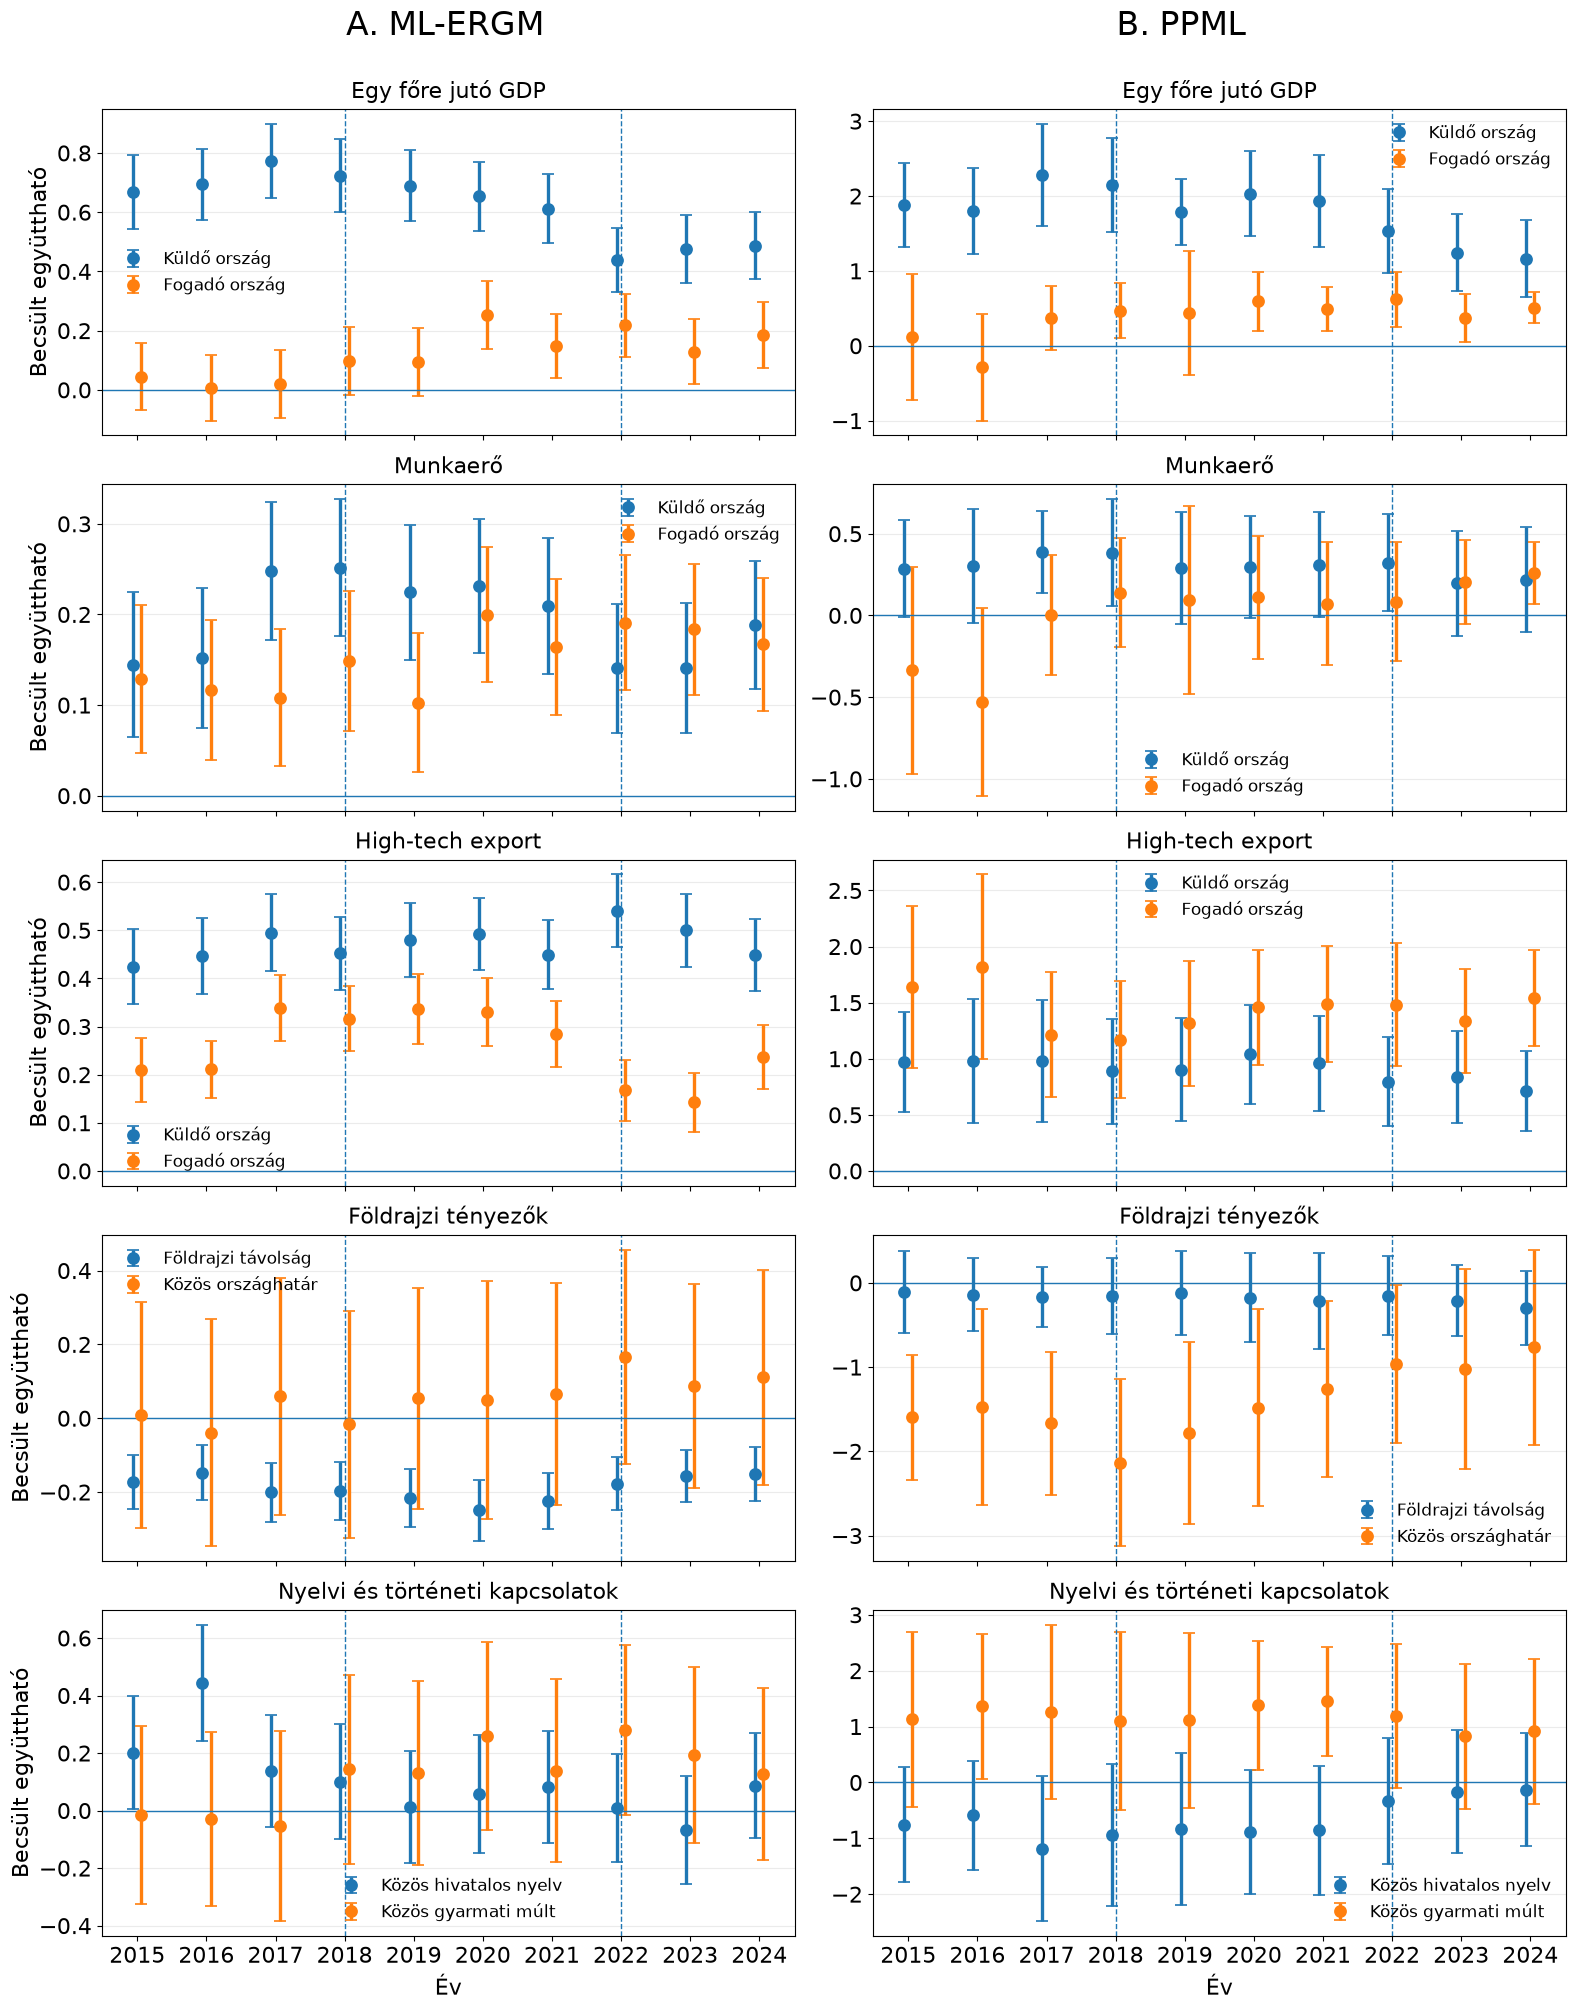

In [55]:
import matplotlib.pyplot as plt

# Panelek és a comparison["Term"] oszlop tényleges értékei
panelek = [
    ("Egy főre jutó GDP", ["log_gdppc_send", "log_gdppc_receiv"]),
    ("Munkaerő", ["log_labor_send", "log_labor_receiv"]),
    ("High-tech export", ["log_hightech_send", "log_hightech_receiv"]),
    ("Földrajzi tényezők", ["log_dist", "contig"]),
    ("Nyelvi és történeti kapcsolatok", ["comlang_off", "colony"]),
]

valtozonevek = {
    "log_hightech_send": "Küldő ország",
    "log_hightech_receiv": "Fogadó ország",
    "log_gdppc_send": "Küldő ország",
    "log_gdppc_receiv": "Fogadó ország",
    "log_labor_send": "Küldő ország",
    "log_labor_receiv": "Fogadó ország",
    "log_dist": "Földrajzi távolság",
    "contig": "Közös országhatár",
    "comlang_off": "Közös hivatalos nyelv",
    "colony": "Közös gyarmati múlt",
}

fig, axes = plt.subplots(
    5, 2,
    figsize=(16, 20),
    sharex=True
)

for i, (panelnev, valtozok) in enumerate(panelek):
    for j, modell in enumerate(["ML-ERGM", "PPML"]):
        ax = axes[i, j]

        for k, valtozo in enumerate(valtozok):
            d = (
                comparison[comparison["Term"] == valtozo]
                .sort_values("Year")
            )

            if modell == "ML-ERGM":
                becsles = d["Estimate_ML_ERGM"]
                se = d["Std_Error_ML_ERGM"]
            else:
                becsles = d["Estimate_PPML"]
                se = d["Std_Error_PPML"]

            eltolas = (k - (len(valtozok) - 1) / 2) * 0.12

            ax.errorbar(
                d["Year"] + eltolas, becsles,
                yerr=1.96 * se,
                fmt="o", 
                markersize=8, 
                capsize=4,
                elinewidth=2.4,
                capthick=2.4,
                markeredgewidth=1.2,
                linewidth=1.8,
                label=valtozonevek[valtozo]
            )

        ax.axhline(0, linewidth=1)
        ax.axvline(2018, linestyle="--", linewidth=1)
        ax.axvline(2022, linestyle="--", linewidth=1)

        ax.set_title(panelnev, fontsize=16, pad=8)
        ax.set_xticks(range(2015, 2025))
        ax.tick_params(axis="both", labelsize=16)
        ax.grid(axis="y", alpha=0.25)

        if j == 0:
            ax.set_ylabel("Becsült együttható", fontsize=16)

        if i == 4:
            ax.set_xlabel("Év", fontsize=16)

        if len(valtozok) > 1:
            ax.legend(fontsize=12, frameon=False)

# Modellnevek a két oszlop felett
fig.text(0.29, 0.99, "A. ML-ERGM", ha="center", fontsize=24)
fig.text(0.75, 0.99, "B. PPML", ha="center", fontsize=24)

fig.tight_layout(rect=[0, 0, 1, 0.975])
plt.show()